In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os
import random

from collections import Counter
from pathlib import Path

# from google.colab import drive
# drive.mount('/content/drive')


data_path = Path("/kaggle/input/datasets/ismailbenmezi/datasetneurovesion/Data")
print(data_path.exists())

ModuleNotFoundError: No module named 'cv2'

: 

In [ ]:
print(list(data_path.iterdir()))

[PosixPath('/kaggle/input/datasets/ismailbenmezi/datasetneurovesion/Data/glioma'), PosixPath('/kaggle/input/datasets/ismailbenmezi/datasetneurovesion/Data/meningioma'), PosixPath('/kaggle/input/datasets/ismailbenmezi/datasetneurovesion/Data/notumor'), PosixPath('/kaggle/input/datasets/ismailbenmezi/datasetneurovesion/Data/pituitary')]


In [ ]:
image_extensions = {".jpg" , ".jpeg" , ".png" , ".bmp"}

for class_path in data_path.iterdir():
    if class_path.is_dir():
        images = [
            file for file in class_path.iterdir()
            if file.suffix.lower() in image_extensions
        ]
        print(f"{class_path.name} => {len(images)}, images")

glioma => 1621, images
meningioma => 1645, images
notumor => 2000, images
pituitary => 1757, images


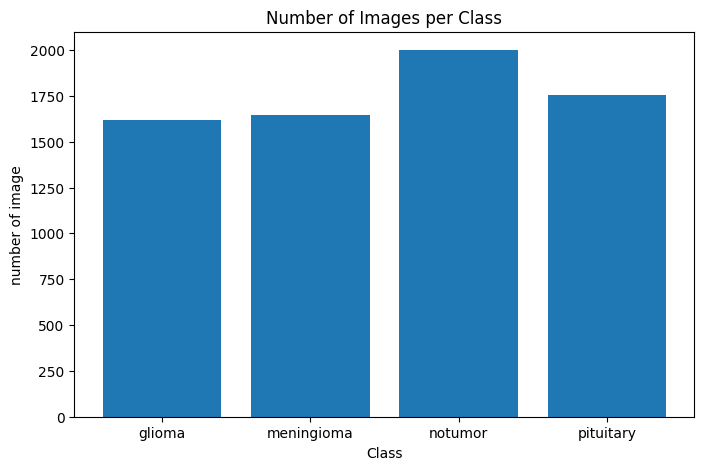

In [ ]:
class_count = {}

for class_path in data_path.iterdir():
    if class_path.is_dir():
        images = [
            file for file in class_path.iterdir()
            if file.suffix.lower() in image_extensions
        ]

        class_count[class_path.name] = len(images)


plt.figure(figsize=(8 , 5))

plt.bar(class_count.keys() , class_count.values())
plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("number of image")
plt.show()

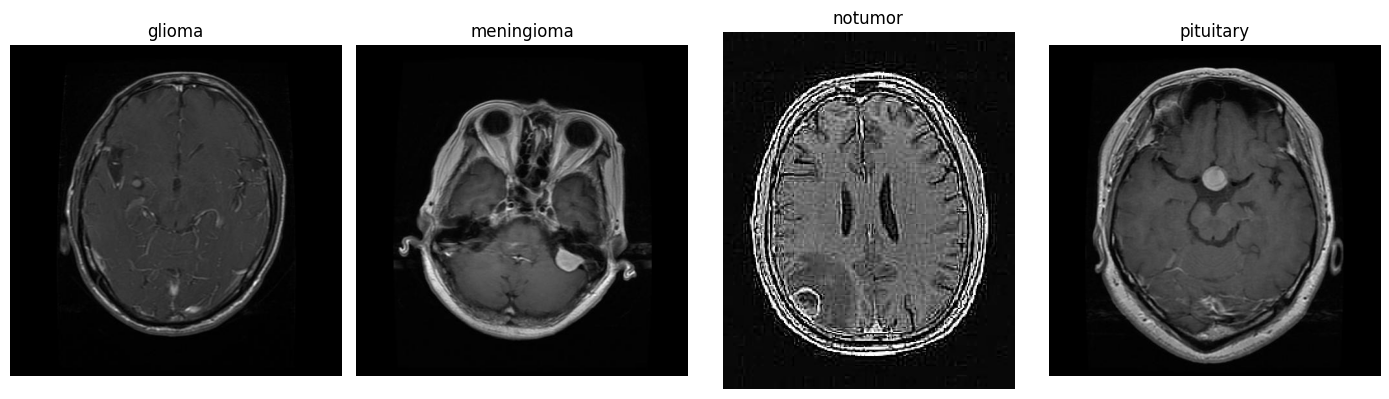

In [ ]:
fix , axes = plt.subplots(1 , 4, figsize=(14 , 4))

for ax , class_name in zip(axes , class_count.keys()):
    class_path = data_path / class_name

    # display(class_path)
    # display(class_name)

    images = [
        file for file in class_path.iterdir()
        if file.suffix.lower() in image_extensions
    ]

    # display(images)

    image_path = random.choice(images)
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image , cv2.COLOR_BGR2RGB)

    # display(image)

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
image_size = []
unreadable_images = []

for class_path in data_path.iterdir():
    if class_path.is_dir():
        for image_path in class_path.iterdir():
            if image_path.suffix.lower() in image_extensions:
                image = cv2.imread(str(image_path))

                if image is None:
                    unreadable_images.append(image_path)
                else:
                    height , width = image.shape[:2]
                    image_size.append((height , width))

print("readable images: " , len(image_size))
print("unreadable images: " , len(unreadable_images))
print("diffreant image size:" , len(set(image_size)))
print("Most common sizes:" , Counter(image_size).most_common(10))

KeyboardInterrupt: 